# BENCHMARK RETINAFACE — CPU / GPU

**Báo cáo thực nghiệm | Face Detection using RetinaFace and U-Net**  
**Vai trò:** Kiểm thử và đánh giá hiệu năng RetinaFace  

> **Phạm vi:** Đo `RetinaFaceDetector.detect()` cho ảnh tĩnh, *không phải* toàn bộ pipeline U-Net/crop/blur. 
**Các tiêu chí bắt buộc:** phần cứng, **batch size**, **resolution** (độ phân giải) và **số mẫu** đều được trình bày và phân tích bên dưới.

## 1. Quy trình đo và nguồn dữ liệu

Dựa trên mã `benchmark.py`, phép đo thực hiện như sau:

1. Tìm ảnh JPG/JPEG/PNG trong `data/test_images` và sắp xếp theo tên.
2. Nạp mô hình **RetinaFaceDetector (ResNet-50 mặc định)** *một lần* cho mỗi phiên chạy.
3. Chạy **3 lượt warm-up** trên ảnh hợp lệ đầu tiên.
4. Đọc từng ảnh bằng OpenCV và gọi `detector.detect(image)` **1 lần/ảnh**. Trên CUDA có `torch.cuda.synchronize()` trước/sau phép đo.
5. Ghi thời gian tính bằng `time.perf_counter()` trong đơn vị **ms**; lưu `detail.csv` và `summary.json`.
6. FPS tính bằng **số lượt suy luận thành công / tổng thời gian gọi `detect()`**, không gồm đọc ảnh, khởi tạo mô hình, xuất ảnh hoặc hiển thị GUI.

**Batch size thực tế = 1**: mã xử lý từng ảnh bằng `detector.detect`, không gọi API `detect_batch`; `--repeats 1` là **1 lần lặp trên mỗi ảnh**, không phải batch size. Số `batch_size: 16` trong cấu hình U-Net của nhóm không áp dụng cho phép đo RetinaFace này.

**Hai lần đo được thực hiện trên hai máy/môi trường khác nhau**; vì thế không thể khẳng định mọi khác biệt tốc độ hoàn toàn do GPU.

## 2. Đọc dữ liệu gốc (được nhúng trong notebook)

Các bảng và biểu đồ phía dưới được tính lại trực tiếp từ **98 dòng CPU + 98 dòng GPU** của `detail.csv`, thay vì điền số thống kê thủ công.

In [ ]:
import base64, io, json, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PAYLOAD = "eNrNW11zm8yS/iuncr11ls+8q606F5JAMo5mWCyQBHcWSrAAOd4jy8Bs7X/fbmDGoWUSay+29uKtN7GZ6emepz+fyX99SV8u/3r4/vp4LP+ent++/Pvfvvz1F/xkuRGHxSSPd7xcLZOX/XJzibd6ubo7vCR3Dz9Xy6fycXv4eZjXp3jLy7Spz/HuodyfuL0zdLG64xr8XYefl+nz/Vuaad82LntlzrReLR6cVTit2Nr+z3SZnlk4bfi8Mnmendm6arjD9FUe2Lyp/2PdVHxe9t8f6yhotIo53uXxefa8cryKi+DMRGzxpqpWjtv4Tlatctb4a7K2kWtZv5bV/rwSfggyj5XBQ/fCc2as3MlqNVVn1eRZ+Xx4VoZnbeCsoaet8qyi8vhayot6eW7F8kCur0G+Dntc/NA7h9r57AQv/ffxuZdtrE4vVdJUNeirwXrhOy7aR+MiAvukZF0q15nDdanhr1t5NcunF+64NdHRkjr6vY5wD/bKCSx+xHWuzpziwsOC2sZW64b3aPgOO8Paxg9TC86pE9vUbN7bJpwObMOFZ8E54T6npj+3BJx/qGPo9jqCDkPbdLZF2+QR3P+U6Og2/VlrdhycVa4/c7A3W1u6H8ZEJpMyxVBmbMH9w/89nYfswoVrEZkSO/U7dryKgUyeTwGrGeg71fjaMvywIDIjKVMfyoxMtCuDtSwHnecW4JCRtRI/rsQPfDM9g14g04N1rOZHy/SdiKyT+HHNK5nrSiDWAcuAu0yAHw7u01f3mQ3vM0x1uE8Bf7dYXgDWmU1sJDFUEwzpXMRwVsAmfMMBJ1xk+nCtV/VrGzan+AP7AFYYYAHutPbDYKhrLnHkjeFIZ6IA7BY0jjQqBuUe1dVAHLE8RezqjOIolzjyBJXpg+8iduH8AmKXSWVyad88GMrMs6aTCfZdIxaonhJHnn6F3da3PfAxiHsOyB3a1pC25cdr38YYDXpW6NsECw2XcTZPSdzzQK8KzhvA3UI8ETGVKeNQ45P7bLHQymQY2w3A20CmL2MtYIzEk6qzD2LYAvwSXxHT3j6w7/BO4P5bmTrPwY9yij0mc5iQOQzOaP2CH8gL4P855KPhWYXCjyD46dbDWQudN5bGhEvOKvHDxAhmBRcMc5HOhvgRCj8iGM9FYXCBmEDiJuThXk++/jhugp0ExBM4L4lhQsYhZoyeN4wasJFBMCQUhsQQQ9zJOplhWoGNBPyeyMykTGtUphPDfU7JukKus8fXFTWsg5g/OKsmcxn40JhtDTgv4J3aNpAY0th6LCdFNfi1BpgYnJdDHO/3aEiub7CmAZmI7Utrh6FMoWQ2VCbcE+YHkVk+5pUwIjIDKVP7OJYAQgHTkPNNIlNiSJMYgngOfhm1uRD0rLEOAH9pyDpDrTtKH8MzuqLNf3gnOdaJU53eicQPd9JxvLcxaEpqmkDGII3EIMjZkdneiXAhB1iQzzxiH4mhQGIIzjcFXYOqWxegb1oktusKP6oWiuD8uDZCHSHeInYCEisjiR39Cjv5tOmwE0MstmrM64NzhhI7EcFObENtgfUM5CGoZ5yY3GMklMyGxucuJ4C+AmMeqdt1rnSk+asA22Cej23WWFDDuuSsMn9FJH+lgNE2f0G9hrWXR7ATSezo/DgWtyINcc6v7CProMj82Lc8wE4G9qE4jyR2dH8+kjNDyKt5BPXg0D4yf0GN3dsng7iCdm1xXvtODLHHM4hdDYWdnMYerPHaXGt1+Cm04VljiR9D5S8nBd1irbMr1CQQs1hYkPgRN2odtauIjQ53mYG1O9zL0K6q/oll/tKwd+N50PqV3/ZRkcGH/mEo7LzXPjbWsyDX6uJHAfVTBHEnIrVlLOOOoeJOjr4YyHUQtywd9CbnlHkrfs9b2OuFXpefQ4hBeUFrNEPFHFL3dHWhV6FdoQaHfDe1SX42fKWjrJ8D8IUp9kEyRkI8gPiYMxIHYlk/G76qQ7y+D562mIN7bO1KZJoKO0Jhp13zXjNlmo81E6mdIf719klV7dzFc6bOinWG71DspBI7Jhv1Sagn55ZGaiZT9u4QZ8biuQm2vbQ911Cm7MFM0r+/59jQg/4Fa0MSe4SMPak+2msKF/MPwV1qKJmjvaaHfQn4e0ZkytiTmqN1SN72/jWJBabCkMhGbIR5FuqBPKD1lqniD+TEdGl/sDbAO75AHU3sm8kezGJj9oXer60nhjKhX+lk+tB/fHzeAHKqCzhiVKZQMpvx2A75xKQxyFc1THZVw/Autms+zjpESmq1TMYSi6/Hek2cl1iNT+7UV/OcTMYTHfIg4A5siT4auibkaagRC7JOYiEzR3q3Gutj7tDeJJN5yPI/vBNP1uy0brJ8dSe0j8r63iRC/zRob+KruUxRj9fPUD/kXjXErStnevX7TO/Ktxvs6658G3vlRb/HOA4qjPEkhsHve9+G3DveS2GshlpvPTwvV+eNx86rYT6GPEDOK+dB7vs8qJ3LTc+AcfAtd1iLhqyPlxBPR+Olh7nWIrV6rXrFcLxXBJkN9u984JeQZ9a9fmJ0bqn57cwgtcl5TXle3ozO2Gzow6F+l/fx8x9f/uVv7QT6fDmdHv/Z/D0//3zGGfT3SvvmzafHw7J8TXZci7d65eU/Mw8wBPUi2vOV5Q8RyPgKvclXrMmgJgdbMO0bzg/zaeUdQa/jNPNO+luy3Jzb9eV9CXte4ih5io2Nm+weyth8eEuPsyLZJk+Hba15d/dlatjlAXqU9z0eysOpzJO199Wb3+fpXXRE3fGMsbkp4s3k6XBavOyXi+N+GR394+wUb2uRrPv1zyDjxH/uzKRMn/nL3rDgm+kR8FmDTapvBq8Oaw9tksH+b2nTytk9bu1ibx4E4gbxB/kG9IzBhtPXSP9Vx/I13h7KncHfDltbQ10xFvX7NcluVsa7B7EzZ2VaTl7228VzqwvcS/+NOGx5DrYWyfPmvDPKS3LaNMnWhp8xPKsNNUwvK3l63NZlsoB9TqDPaXMBWwqUyeQ3z4en9KTr6UffNMN72Rn1W7x9+JEam3xv2EWrO8QgjI3SxmBXDc/yfTN5TbaLC3IM7V4iqP1116/2erzzECb0KovJa7cfayBWQp0Ifni9J8SwzY99p6fZ1v5tvS3PWT8dkP8wyx/7balkK7/94Izx7knuh7VxDfcs3vX+xbabydv+VNs7I6m6c+L9Fo3cM11unh71yXN6t/kBeDrvDY5nKeAMRzzDHu5qr2wOd7x9/ZGYM31nIoY3zeE08u3JfkOOp/OJhxfUK2lmaFtx2MHaBvxB+Ybd/znI4H7O39dVluye8v3dBn7Osset/pQYUbZfTp6SZbvP0/4E324n4FMV/N5+AZ972i/Lr3A3iP2L5yZB1MxO6Wny6t1xfb+evSXH2S9YibLO99lf8Psy3W3K/fPDS9zuh/I2YnWc3UULkLvdvO7Ne9tblsJbzOzNctLERvYKGL+gTyTzKtufJuDXD6Dz4uwtpS/PtlGx4LCPg/s8LhfCW9pv3iJZB5GG+z6lJt6TDrKDi5dp334E/2hjVvb/jTXTAWHQzZKpoZoUTWW337RVscOMduo8hw7BwWqdTmNldp2+Z1dkOByGUQA6S6hKclcjnWylJo1O8CGzA3IuTBSkYp7qimUbmzK2kY8JyghyxQjSbMysLru6dTuNz70b2bICqmzogol+iulwZJUdQ9VUaVjlgTyznWKQCpCpydDU/oBBgu6wEG1V3tzGkuF0i04GP8GQQTdsafyKNZI4cZvRdXPLxknPbexYYLcTXqKbwsn7RKhpO94wxi4Sq02tmyJkNzNjfuhB9RVTpslQbNzx1065MFiHZ7iD4oqpVJPoMB1htgJcZ5Lu+hOMGHZibWc7XCeZjLAYmyJobcVAGBCFFTIJgtiAtqxx2rqC7u1qnWJOxrqwGDtc6nd/ZMGgIoM7yMh01ROKsbuqEDOz83OIBXnU8ONtDBhmdohPpGvzdMViXXVtXtfBQ+d1JUvpFlNZou/eofqNyMTRM5UsqlsOlTLKC8H/84B0FMh2SXkEK3lvS+h+4M9UN1uxZWv6MmHaxSJkDqj//JnxgmrFxU7fupHxslsGkrLKQsYV1lzF2RZfEU6niC2ZULLGOokcJ340jzBNsVVj04icXSgjp15qjHY8sYlMMJFlKFljUx7AD6cvGNSEh5G8E1idLGRVC4PEIaEwMjrdAYxBzKO6qXgiijHdBNr/dlYL40JEJ5majCd8dKoTa/g6g/icJuMJd7yRXNdO9+xb2SycCvo47Rmu0xSzNP84LkCMrejrEy6nBsho9ZMczFnd9BMniXDf+OLlNharhpwG/pZS9stU65pxLPPcE7cyWJCzqw+woqkpoJr+MMyNOnf6eIKTHzrVD2U8iSo13cK6UgA+2jMiU+LVt7JXDNnAvKiu2DKJk9CjTBLYtMULdmTWjcxVO+nmDtVNTgsjOi20kZ2B2IXxXCd21Llic6IPp2g4oaVxkqtXO9EYWw41FLKOt7JVYOs8o3WGrqbFtD5ROQ5ffJEJD+orGa7+3qB3QAbP7GJ5+9qLMg2fYKncGnTD13CEiZG1bFy/M0YMWZzejshQxc2tDBXUusim0dreUCxDLlmGwGwx0r3OgTyLTHxMzigxEiuMQP1Zda96Wr+pu5eFdJ2MJbGMJQb6GceJescy44syUj/FhmK0lG4tK9X0uRRfD9FXk59hprAOMjl5PYR9ZS9XvqbQIN51TE/PLqG/AXbtG1kpu33dF1LGRcaStPqFeasQyz2zpLeMrRPfykiBMaDnoUyvqk3SsZ7Hxok+nXZz9RInHZuu2j6+6qPxREispNrIuhr7ofZF5pBR0hWjNNofQz2I01zCnMlaFmq1MVaofYGITPONTBT2g4K+PuTqBU5q/Wadxq9YRdkjQ8x5nl1G1l0zD47ETFb9pt+tqTx8Sduvq38Tb8WtzBOy1DRG/Jl1wh55Sms+iys2Jhrp6YI2/5A7t+Sd+2omEunti0qwAeYtqG0MRljvP7NN2D8GNGZaMo/4zod1KcR2fG0FMel4G9PUzjbCgti/kHWDPfpiKsd6j7xmhG8UU3Qcvzc/JK+GP8EwtfdNa75QzrPc0XkW9i88dKk8Q6373TkxZ3ySWcIXN5wy1J9gllAO5Auil+zL3N/2ZYz2qqF8ReiKcXuAHekrp88wSp2/KXvIyez/nk1yv0Lv8pWhHk7WgD7N/wWbdNg+PL3/juvJcvEj3rUsy1N8qkuUdbi71z/BJuFc9p+xGUEuyRRDtTdbJuK4QVZnOTFTZPjm+J9VIdPB8EX6hgdsrhiojiHaTPK9ubkc5i0jYylW4rSpku1CS/VJlezuf/QMQMt2qG/MTY6MT2ok+v4DFugXduoUb8tzsn2AfewT7Ifz8LJnQ+Q3Zry7fz3sZh98w+Q3r3vjoQRZ572xKHYmL2NjcknuehYGZz15cc0SGXoZb23F/vj4Ytzx/sAmYf8bWB8xRKlT6IqdCgN8bYr/kuK3TBIy3BxfXf+eSXqf1fff/WqLHei6vyt/JM+zXjbOQaEu+CST5Lf/6iaFnvhzbBLo1uFHnvk00Xqm8LgBP4OzPXtLsO2O63DvomVdlpv8sJxAvdX/eT5r2a/VfFZ+X/Iz+AEyTz07OWvvsdtncUnms+5+58gSldrjdnF+3L2ADuXb/mhlD+Us9JZJsze0DLD36i0nJ2/5C9O2nsEavUzFOQNd6sMWcI2s1LyXt2MXzz0EmzWyYPpb+lxkjzuWRXdltDfv88e5/go4QeapgPNe9maQgS4aMlIQD4zHLS975gj24bjPzxjW70//lm3K+1m4fmfX9ih7bh0h/06+/Pf/AGzdDQ8="
source_bytes = {name: base64.b64decode(content) for name, content in json.loads(zlib.decompress(base64.b64decode(PAYLOAD)).decode("utf-8")).items()}

def get_data(device):
    detail = pd.read_csv(io.BytesIO(source_bytes[f"{device}/detail.csv"]), encoding="utf-8-sig")
    summary = json.loads(source_bytes[f"{device}/summary.json"].decode("utf-8"))
    detail["device"] = device.upper()
    detail["width"] = pd.to_numeric(detail["width"], errors="coerce")
    detail["height"] = pd.to_numeric(detail["height"], errors="coerce")
    detail["latency_ms"] = pd.to_numeric(detail["latency_ms"], errors="coerce")
    detail["faces"] = pd.to_numeric(detail["faces"], errors="coerce")
    detail["megapixels"] = detail["width"] * detail["height"] / 1_000_000
    return detail, summary

cpu, s_cpu = get_data("cpu")
gpu, s_gpu = get_data("gpu")
assert len(cpu) == len(gpu) == 98
assert set(cpu.test_case) == set(gpu.test_case)
assert set(cpu.status) == set(gpu.status) == {"OK"}
print("Đã nạp dữ liệu nguồn:",len(cpu),"ảnh CPU +",len(gpu),"ảnh GPU")
display(cpu.head(3))

Đã nạp dữ liệu nguồn: 98 ảnh CPU + 98 ảnh GPU


,test_case,filename,width,height,faces,latency_ms,status,error,device,megapixels
0,TC-001,TC-001.jpg,1024,768,1,2435.497,OK,NaN,CPU,0.786432
1,TC-002,TC-002.jpg,2074,3687,0,12880.329,OK,NaN,CPU,7.646838
2,TC-003,TC-003.jpg,318,398,2,651.636,OK,NaN,CPU,0.126564


## 3. Phần cứng và môi trường thực nghiệm

Phân biệt rõ thông tin **có bằng chứng** từ file JSON và thông tin **không được ghi lại**:

| Thông số | CPU (máy 1) | GPU (máy 2) |
|---|---|---|
| Thiết bị suy luận | CPU | NVIDIA GeForce **RTX 3060 Laptop GPU** |
| Dung lượng VRAM GPU | Không áp dụng | **6144 MiB (6 GiB)** theo `nvidia-smi`/PyTorch |
| Driver NVIDIA | Không áp dụng | **546.30** theo Terminal của máy mới |
| PyTorch | `2.15.0+cpu` | `2.7.1+cu118` |
| CUDA được PyTorch sử dụng | Không | Có (CUDA 11.8 build) |
| Hệ điều hành trong log | Windows 11 build 26300 | Windows build 26200 (chuỗi ghi `Windows-10`) |
| CPU model / RAM | **Không có trong log** | **Không có trong log** |
| Mô hình detector | RetinaFace mặc định ResNet-50 | RetinaFace mặc định ResNet-50 |

Không tự suy ra tên CPU, RAM hay TDP khi bộ log không cung cấp.

In [ ]:
hardware = pd.DataFrame([
    {"Thiết bị":"CPU (máy 1)","Model":"RetinaFace ResNet-50", "PyTorch":s_cpu["torch_version"],"CUDA":s_cpu["cuda_available"],"OS":s_cpu["os"],"Nạp mô hình (s)":s_cpu["model_load_seconds"],"GPU":"Không áp dụng","VRAM tổng (MiB)":np.nan},
    {"Thiết bị":"GPU (máy 2)","Model":"RetinaFace ResNet-50", "PyTorch":s_gpu["torch_version"],"CUDA":s_gpu["cuda_available"],"OS":s_gpu["os"],"Nạp mô hình (s)":s_gpu["model_load_seconds"],"GPU":"RTX 3060 Laptop","VRAM tổng (MiB)":6144},
])
display(hardware)

,Thiết bị,Model,PyTorch,CUDA,OS,Nạp mô hình (s),GPU,VRAM tổng (MiB)
0,CPU (máy cũ),RetinaFace ResNet-50,2.15.0+cpu,False,Windows-11-10.0.26300-SP0,9.117,Không áp dụng,NaN
1,GPU (máy mới),RetinaFace ResNet-50,2.7.1+cu118,True,Windows-10-10.0.26200-SP0,13.669,RTX 3060 Laptop,6144.0


## 4. Batch size, số mẫu và độ phân giải ảnh

- **Batch size = 1** ảnh/lượt, xử lý tuần tự. Hai phép đo sử dụng cùng danh sách **98 ảnh khác nhau**.
- `repeats_per_image = 1`, `warmup_inferences = 3` cho mỗi thiết bị.
- Tổng cộng **196 lượt đo chính thức** (98 CPU + 98 GPU), không tính 6 lượt warm-up. **Không phải 196 ảnh độc lập**.
- Độ phân giải được lấy **riêng cho từng ảnh** từ cột `width`, `height` của `detail.csv`, *không giả định tất cả ảnh là 1024×1024*.
- Có một trường hợp đặc biệt **TC-114 có kích thước 1×1**; phép đo này được giữ lại đúng như log và sẽ được lưu ý khi diễn giải latency.

In [ ]:
config = pd.DataFrame([
    {"Thiết bị":"CPU", "Số ảnh độc lập":s_cpu["image_count"], "Batch size thực tế":1,"Số lần/ảnh":s_cpu["repeats_per_image"],"Warm-up":s_cpu["warmup_inferences"], "Inference thành công":s_cpu["successful_inferences"],"Lỗi":s_cpu["failed_inferences"]},
    {"Thiết bị":"GPU", "Số ảnh độc lập":s_gpu["image_count"], "Batch size thực tế":1,"Số lần/ảnh":s_gpu["repeats_per_image"],"Warm-up":s_gpu["warmup_inferences"], "Inference thành công":s_gpu["successful_inferences"],"Lỗi":s_gpu["failed_inferences"]}
])
display(config)
res = cpu.copy()
res["resolution"] = res.width.astype("Int64").astype(str) + "×" + res.height.astype("Int64").astype(str)
print(f"Số độ phân giải khác nhau: {res.resolution.nunique()}")
print(f"Rộng: {int(res.width.min())}–{int(res.width.max())} px | Cao: {int(res.height.min())}–{int(res.height.max())} px")
print(f"Số megapixel: {res.megapixels.min():.6f}–{res.megapixels.max():.2f} MP")
print("Các độ phân giải thường gặp:")
display(res.resolution.value_counts().head(12).rename_axis("Độ phân giải").reset_index(name="Số ảnh"))

,Thiết bị,Số ảnh độc lập,Batch size thực tế,Số lần/ảnh,Warm-up,Inference thành công,Lỗi
0,CPU,98,1,1,3,98,0
1,GPU,98,1,1,3,98,0


Số độ phân giải khác nhau: 48
Rộng: 1–4000 px | Cao: 1–3687 px
Số megapixel: 0.000001–12.00 MP
Các độ phân giải thường gặp:


,Độ phân giải,Số ảnh
0,1024×1024,35
1,1024×728,4
2,1024×576,4
3,1024×683,4
4,1024×682,4
5,1024×575,2
6,1024×768,2
7,1024×688,2
8,1024×788,2
9,689×486,1


,Nhóm độ phân giải,Số ảnh
0,"≤ 0,5 MP",13
1,"0,5–1 MP",37
2,1–2 MP,45
3,> 2 MP,3


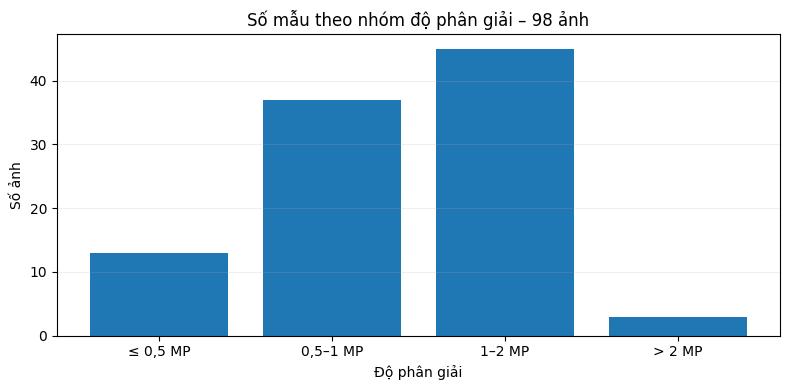

In [ ]:
# Chia nhóm theo số pixel thật của từng ảnh; đây là phân nhóm phân tích, không phải thí nghiệm resize.
limits = [0, 0.5, 1.0, 2.0, float('inf')]
labels = ["≤ 0,5 MP", "0,5–1 MP", "1–2 MP", "> 2 MP"]
res["Nhóm độ phân giải"] = pd.cut(res.megapixels, bins=limits, labels=labels, include_lowest=True)
resolution_counts = res["Nhóm độ phân giải"].value_counts(sort=False).rename("Số ảnh").reset_index()
display(resolution_counts)
plt.figure(figsize=(8,4))
plt.bar(resolution_counts["Nhóm độ phân giải"].astype(str),resolution_counts["Số ảnh"])
plt.title("Số mẫu theo nhóm độ phân giải – 98 ảnh")
plt.ylabel("Số ảnh");plt.xlabel("Độ phân giải");plt.grid(axis="y",alpha=.2)
plt.tight_layout();plt.show()

## 5. Kết quả latency, FPS và VRAM

**Định nghĩa:**
- **Latency mean:** trung bình thời gian gọi `detect()` trên 98 lượt.
- **P50:** phân vị thứ 50, **P95:** phân vị thứ 95.
- **FPS inference-only:** `1000 × N / tổng latency_ms`, không phải FPS video/end-to-end.
- **Peak GPU allocated / reserved:** đỉnh bộ nhớ do **PyTorch** cấp phát / dự trữ sau warm-up; không đại diện cho tổng bộ nhớ hiển thị trong `nvidia-smi`.

Các bảng dưới đây được tính trực tiếp từ 98 dòng dữ liệu chi tiết rồi đối chiếu số tổng hợp lưu trong JSON.

In [ ]:
def metrics(df, summary):
    ok = df[df.status == "OK"].latency_ms.dropna().to_numpy()
    return {
        "Thiết bị":summary["device"].upper(),
        "Ảnh thành công":len(ok),
        "Mean (ms)":round(float(ok.mean()),3),
        "P50 (ms)":round(float(np.percentile(ok,50)),3),
        "P95 (ms)":round(float(np.percentile(ok,95)),3),
        "Min (ms)":round(float(ok.min()),3),
        "Max (ms)":round(float(ok.max()),3),
        "FPS inference-only":round(float(1000*len(ok)/ok.sum()),3),
        "Peak allocated (MiB)":summary["peak_gpu_allocated_mb"],
        "Peak reserved (MiB)":summary["peak_gpu_reserved_mb"],
    }
results=pd.DataFrame([metrics(cpu,s_cpu),metrics(gpu,s_gpu)])
display(results)
assert abs(results.loc[0,"Mean (ms)"]-s_cpu["latency_mean_ms"]) <= .002
assert abs(results.loc[1,"Mean (ms)"]-s_gpu["latency_mean_ms"]) <= .002
assert abs(results.loc[0,"FPS inference-only"]-s_cpu["inference_only_fps"]) <= .002
assert abs(results.loc[1,"FPS inference-only"]-s_gpu["inference_only_fps"]) <= .002
speedup_mean=s_cpu["latency_mean_ms"]/s_gpu["latency_mean_ms"]
speedup_fps=s_gpu["inference_only_fps"]/s_cpu["inference_only_fps"]
print(f"Tỷ số latency CPU/GPU (theo mean): {speedup_mean:.2f}×")
print(f"Tỷ số FPS GPU/CPU: {speedup_fps:.2f}×")
print(f"Allocated VRAM đỉnh: {s_gpu['peak_gpu_allocated_mb']:.3f} MiB")
print(f"Reserved VRAM đỉnh: {s_gpu['peak_gpu_reserved_mb']:.3f} MiB")

,Thiết bị,Ảnh thành công,Mean (ms),P50 (ms),P95 (ms),Min (ms),Max (ms),FPS inference-only,Peak allocated (MiB),Peak reserved (MiB)
0,CPU,98,3419.715,3248.914,7057.267,83.216,13612.330,0.292,NaN,NaN
1,CUDA,98,79.182,65.487,146.086,29.426,284.863,12.629,835.744,1410.0


Tỷ số latency CPU/GPU (theo mean): 43.19×
Tỷ số FPS GPU/CPU: 43.25×
Allocated VRAM đỉnh: 835.744 MiB
Reserved VRAM đỉnh: 1410.000 MiB


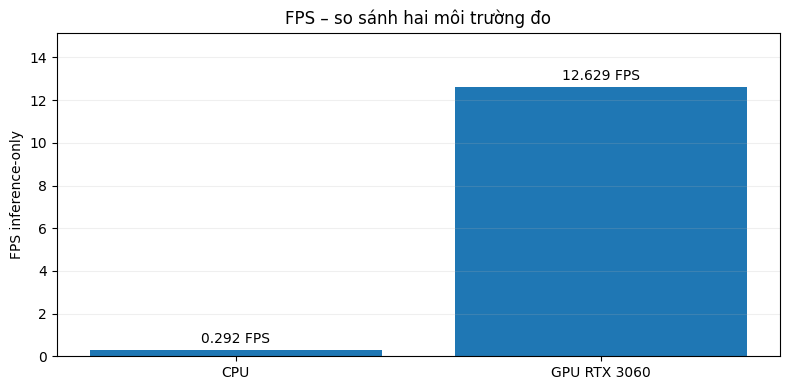

In [ ]:
fig, ax = plt.subplots(figsize=(8,4))
bars=ax.bar(["CPU","GPU RTX 3060"],results["FPS inference-only"].values)
ax.bar_label(bars,fmt="%.3f FPS",padding=3)
ax.set_ylabel("FPS inference-only");ax.set_title("FPS – so sánh hai môi trường đo")
ax.set_ylim(0,max(results["FPS inference-only"])*1.2)
ax.grid(axis="y",alpha=.2);plt.tight_layout();plt.show()

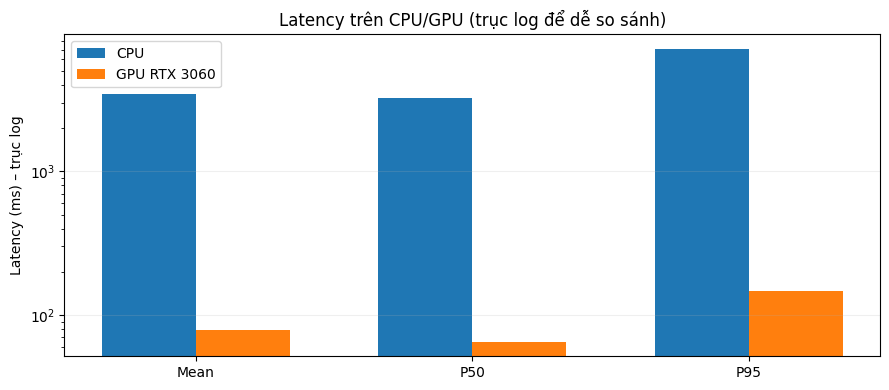

In [ ]:
fig, ax=plt.subplots(figsize=(9,4))
x=np.arange(3);width=.34
cpu_vals=[s_cpu[k] for k in ("latency_mean_ms","latency_p50_ms","latency_p95_ms")]
gpu_vals=[s_gpu[k] for k in ("latency_mean_ms","latency_p50_ms","latency_p95_ms")]
ax.bar(x-width/2,cpu_vals,width,label="CPU")
ax.bar(x+width/2,gpu_vals,width,label="GPU RTX 3060")
ax.set_yscale("log")
ax.set_xticks(x,["Mean","P50","P95"])
ax.set_ylabel("Latency (ms) – trục log")
ax.set_title("Latency trên CPU/GPU (trục log để dễ so sánh)")
ax.legend();ax.grid(axis="y",alpha=.2);plt.tight_layout();plt.show()

## 6. Latency theo resolution và các mẫu xử lý chậm

Dưới đây là các thống kê theo **độ phân giải đầu vào đã quan sát được**. Đây là phân tích hồi cứu trên bộ 98 ảnh không đồng nhất, **không** phải benchmark có kiểm soát khi thay đổi kích thước của *cùng một ảnh*.

In [ ]:
paired=cpu[["test_case","width","height","megapixels","faces","latency_ms"]].merge(
    gpu[["test_case","width","height","faces","latency_ms"]],on="test_case",suffixes=("_cpu","_gpu"),validate="one_to_one")
assert (paired.width_cpu==paired.width_gpu).all() and (paired.height_cpu==paired.height_gpu).all()
paired["Nhóm MP"]=pd.cut(paired.megapixels,bins=[0,.5,1,2,float("inf")],labels=["≤ 0,5 MP","0,5–1 MP","1–2 MP","> 2 MP"],include_lowest=True)
by_mp=paired.groupby("Nhóm MP",observed=True).agg(
    so_anh=("test_case","count"),cpu_mean_ms=("latency_ms_cpu","mean"),gpu_mean_ms=("latency_ms_gpu","mean"),
    cpu_p95_ms=("latency_ms_cpu",lambda x:np.percentile(x,95)),gpu_p95_ms=("latency_ms_gpu",lambda x:np.percentile(x,95)))
display(by_mp.round(2))
print("5 ảnh GPU xử lý chậm nhất:")
display(paired.nlargest(5,"latency_ms_gpu")[["test_case","width_cpu","height_cpu","megapixels","faces_gpu","latency_ms_gpu","latency_ms_cpu"]].round(3))

,so_anh,cpu_mean_ms,gpu_mean_ms,cpu_p95_ms,gpu_p95_ms
Nhóm MP,,,,,
"≤ 0,5 MP",13,934.52,67.70,1588.69,94.07
"0,5–1 MP",37,2527.95,64.58,3162.92,101.70
1–2 MP,45,4308.24,84.03,6759.93,131.15
> 2 MP,3,11859.54,236.36,13539.13,283.63


5 ảnh GPU xử lý chậm nhất:


,test_case,width_cpu,height_cpu,megapixels,faces_gpu,latency_ms_gpu,latency_ms_cpu
1,TC-002,2074,3687,7.647,0,284.863,12880.329
67,TC-068,4000,3000,12.000,1,272.569,13612.330
69,TC-070,1280,720,0.922,1,158.746,2849.214
63,TC-064,1920,1080,2.074,1,151.660,9085.959
13,TC-014,1200,1600,1.920,8,148.398,7045.699


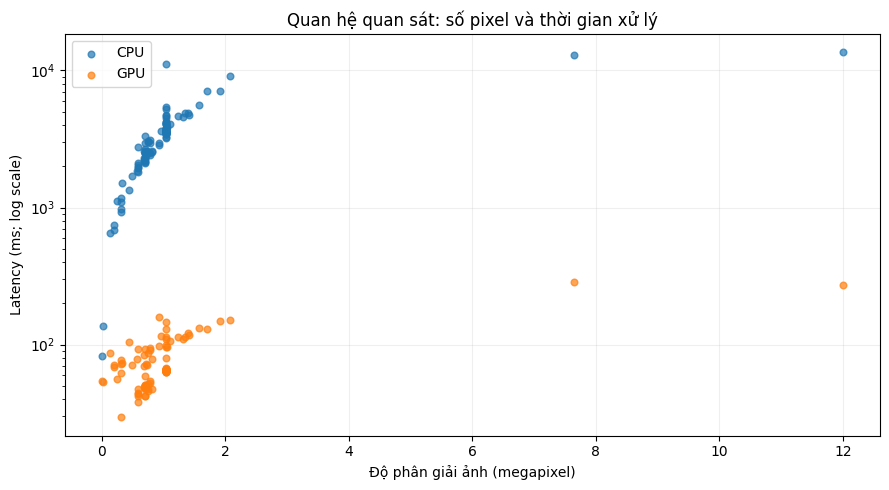

In [ ]:
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(paired.megapixels,paired.latency_ms_cpu,alpha=.7,label="CPU",s=23)
ax.scatter(paired.megapixels,paired.latency_ms_gpu,alpha=.7,label="GPU",s=23)
ax.set_yscale("log")
ax.set_xlabel("Độ phân giải ảnh (megapixel)")
ax.set_ylabel("Latency (ms; log scale)")
ax.set_title("Quan hệ quan sát: số pixel và thời gian xử lý")
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 7. Đối chiếu số mặt phát hiện và chất lượng dữ liệu đo

Mỗi ảnh cùng mã TC xuất hiện ở cả hai lần đo, cùng độ phân giải. Có thể kiểm tra **số mặt được phát hiện** có khớp giữa CPU và GPU hay không. Đây chỉ là kiểm tra tính nhất quán số lượng, **không thay thế nghiệm thu độ chính xác bbox/mask**.

In [ ]:
print("Số ảnh trùng mã CPU/GPU:",len(paired))
print("Số ảnh khác kích thước:",int(((paired.width_cpu!=paired.width_gpu)|(paired.height_cpu!=paired.height_gpu)).sum()))
print("Số ảnh khác số mặt CPU/GPU:",int((paired.faces_cpu!=paired.faces_gpu).sum()))
print("Số lượt inference lỗi CPU/GPU:",s_cpu["failed_inferences"],"/",s_gpu["failed_inferences"])
print("Ảnh có kích thước rất nhỏ (< 10×10):")
display(paired[(paired.width_cpu<10)|(paired.height_cpu<10)][["test_case","width_cpu","height_cpu","faces_cpu","faces_gpu","latency_ms_cpu","latency_ms_gpu"]])

Số ảnh trùng mã CPU/GPU: 98
Số ảnh khác kích thước: 0
Số ảnh khác số mặt CPU/GPU: 0
Số lượt inference lỗi CPU/GPU: 0 / 0
Ảnh có kích thước rất nhỏ (< 10×10):


,test_case,width_cpu,height_cpu,faces_cpu,faces_gpu,latency_ms_cpu,latency_ms_gpu
93,TC-114,1,1,0,0,83.216,54.609


## 8. Khả năng tái lập (reproduce)

**Chạy notebook chỉ để xem báo cáo:** cài `pandas`, `numpy`, `matplotlib`, `ipykernel`, sau đó chọn **Run All** trong VS Code/Jupyter. Notebook dùng dữ liệu nhúng nên **không cần tải mô hình/CUDA** để vẽ lại biểu đồ.

**Muốn đo lại trên dự án:** đặt `benchmark.py` trong thư mục gốc cùng `src/detection/retinaface.py` và thư mục `data/test_images`, kích hoạt môi trường Python phù hợp rồi thực hiện:

```powershell
# CPU
.\.venv\Scripts\python.exe benchmark.py --images data/test_images --device cpu --warmup 3 --repeats 1 --out benchmark/cpu

# GPU CUDA
.\.venv\Scripts\python.exe benchmark.py --images data/test_images --device cuda --warmup 3 --repeats 1 --out benchmark/gpu
```

Mỗi lần chạy tạo `detail.csv` và `summary.json`. Để thử batch size >1, cần một benchmark riêng sử dụng API batch (nếu có), không thể đổi `--repeats` thành batch size.

## 9. Nhận xét, giới hạn và kết luận

**Kết quả từ dữ liệu thực:**
- CPU: **98/98** lượt thành công, mean **3419,715 ms**, P50 **3248,914 ms**, P95 **7057,267 ms**, khoảng **0,292 FPS**.
- RTX 3060 Laptop: **98/98** lượt thành công, mean **79,182 ms**, P50 **65,487 ms**, P95 **146,086 ms**, khoảng **12,629 FPS**.
- Đỉnh PyTorch GPU memory: **835,744 MiB allocated**, **1410,000 MiB reserved**; GPU có **6144 MiB VRAM**.
- FPS GPU gấp khoảng **43,25×** FPS CPU trong **hai môi trường đo**; không diễn giải là cải thiện chỉ do GPU vì phần cứng, phiên bản PyTorch và hệ điều hành không đồng nhất.

**Giới hạn đánh giá:**
1. Mỗi ảnh chỉ đo **một lần**, do đó chưa đủ để ước lượng biến thiên qua nhiều lượt/độ tin cậy thống kê.
2. **Batch size = 1** cho cả CPU/GPU; chưa benchmark batch size 2/4/8/16 hoặc chất lượng khi resize.
3. Độ phân giải đầu vào thay đổi theo ảnh (48 kích thước), và có **TC-114 (1×1)**; so sánh theo độ phân giải chỉ có tính mô tả.
4. Chỉ đo `detect()`, chưa tính thời gian I/O, preprocess toàn pipeline, U-Net, blur, GUI/video.
5. Số liệu VRAM chỉ là mức cấp phát PyTorch, không phải VRAM tổng thiết bị hay VRAM các ứng dụng nền.
6. CPU model/RAM không có trong log và không được tự điền.

**Kết luận:** Bộ benchmark đã đủ các mục **phần cứng, batch size, resolution, số mẫu** và dữ liệu **latency/FPS/VRAM** để trình bày phần đo *RetinaFace inference* trong báo cáo. Việc thử nhiều batch size và benchmark end-to-end là phần mở rộng cần đo mới, không được coi là đã thực hiện.